In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [47]:
# load dataset
data = pd.read_csv('healthcare-dataset-stroke-data.csv')
data.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [48]:
data.shape

(5110, 12)

In [49]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 479.2 KB


In [50]:
data.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [51]:
data.isnull().sum()

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

In [52]:
# drop id and remove invalid gender
data = data.drop(columns=['id'])
data = data[data['gender'] != 'Other']

In [53]:
data['stroke'].value_counts()

stroke
0    4860
1     249
Name: count, dtype: int64

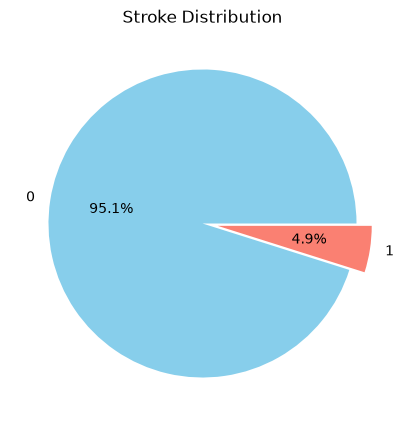

In [54]:
plt.figure(figsize=(5, 5))
data['stroke'].value_counts().plot.pie(
    autopct='%1.1f%%', colors=['skyblue', 'salmon'], explode=[0, 0.1])
plt.title('Stroke Distribution')
plt.ylabel('')
plt.show()

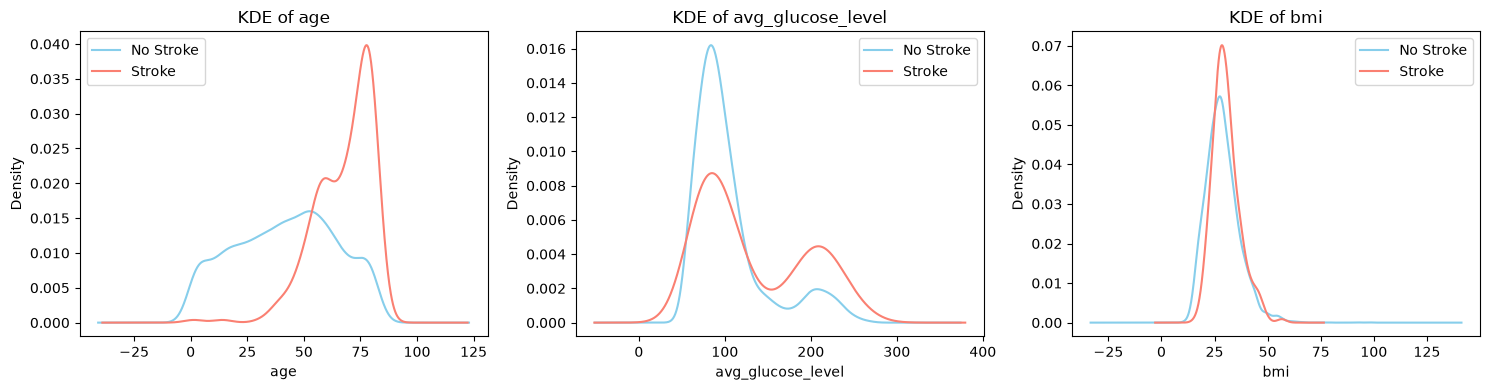

In [55]:
# KDE plots 
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, ['age', 'avg_glucose_level', 'bmi']):
    data[data['stroke'] == 0][col].plot(kind='kde', ax=ax, label='No Stroke', color='skyblue')
    data[data['stroke'] == 1][col].plot(kind='kde', ax=ax, label='Stroke',    color='salmon')
    ax.set_title(f'KDE of {col}')
    ax.set_xlabel(col)
    ax.legend()

plt.tight_layout()
plt.show()

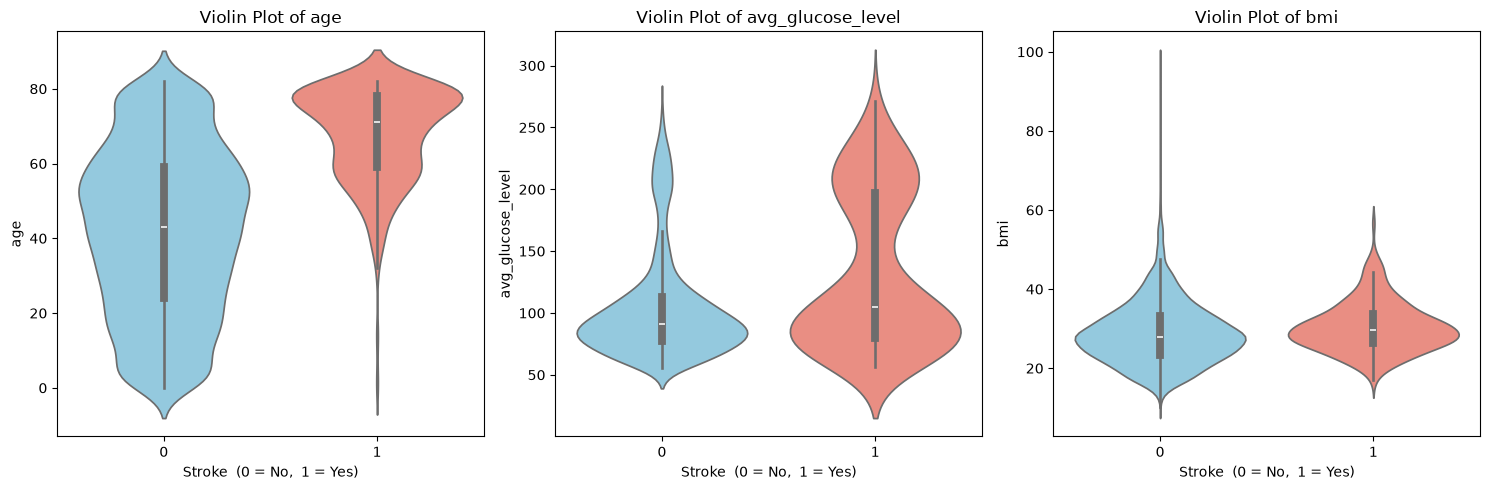

In [56]:
# Violin plots – numerical features by stroke
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, col in zip(axes, ['age', 'avg_glucose_level', 'bmi']):
    sns.violinplot(data=data, x='stroke', y=col, hue='stroke',
                   palette=['skyblue', 'salmon'], legend=False, ax=ax)
    ax.set_title(f'Violin Plot of {col}')
    ax.set_xlabel('Stroke  (0 = No,  1 = Yes)')

plt.tight_layout()
plt.show()

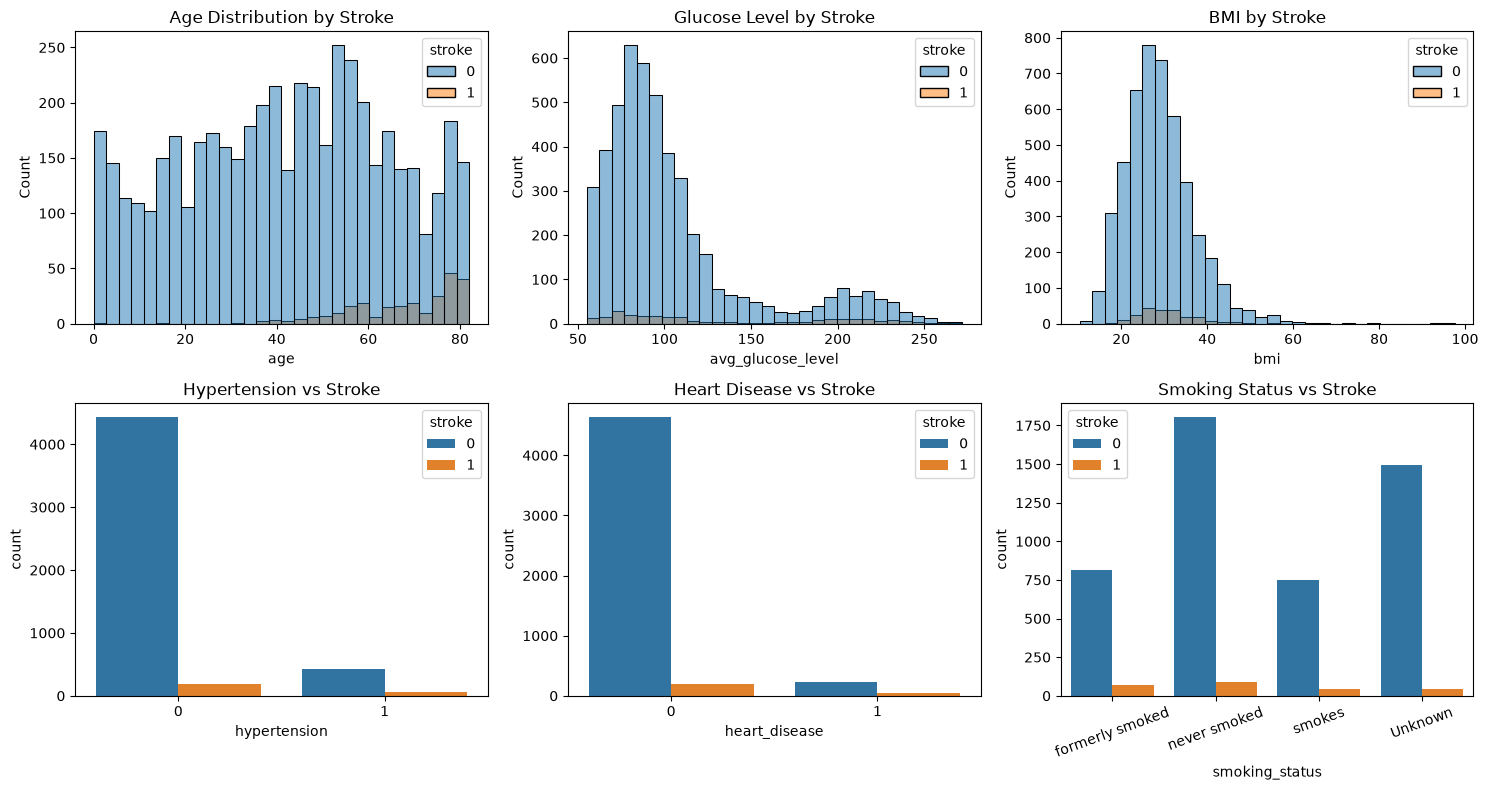

In [57]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

sns.histplot(data=data, x='age',               hue='stroke', bins=30, ax=axes[0][0])
axes[0][0].set_title('Age Distribution by Stroke')

sns.histplot(data=data, x='avg_glucose_level', hue='stroke', bins=30, ax=axes[0][1])
axes[0][1].set_title('Glucose Level by Stroke')

sns.histplot(data=data, x='bmi',               hue='stroke', bins=30, ax=axes[0][2])
axes[0][2].set_title('BMI by Stroke')

sns.countplot(data=data, x='hypertension',  hue='stroke', ax=axes[1][0])
axes[1][0].set_title('Hypertension vs Stroke')

sns.countplot(data=data, x='heart_disease', hue='stroke', ax=axes[1][1])
axes[1][1].set_title('Heart Disease vs Stroke')

sns.countplot(data=data, x='smoking_status', hue='stroke', ax=axes[1][2])
axes[1][2].set_title('Smoking Status vs Stroke')
axes[1][2].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

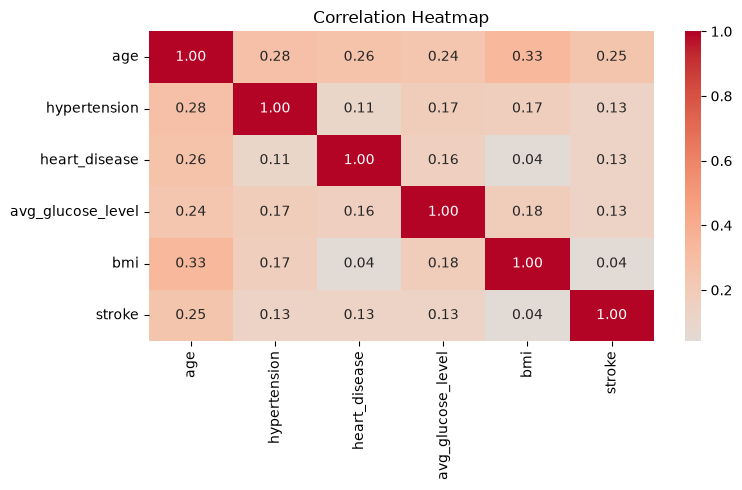

In [58]:
plt.figure(figsize=(8, 5))
num_cols = ['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi', 'stroke']
sns.heatmap(data[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

In [59]:
# fill missing bmi with median
data['bmi'] = data['bmi'].fillna(data['bmi'].median())
data.isnull().sum()

gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64

In [60]:
# encode categorical variables
data = pd.get_dummies(data, drop_first=True)
data.head()

,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke,gender_Male,ever_married_Yes,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,67.0,0,1,228.69,36.6,1,True,True,False,True,False,False,True,True,False,False
1,61.0,0,0,202.21,28.1,1,False,True,False,False,True,False,False,False,True,False
2,80.0,0,1,105.92,32.5,1,True,True,False,True,False,False,False,False,True,False
3,49.0,0,0,171.23,34.4,1,False,True,False,True,False,False,True,False,False,True
4,79.0,1,0,174.12,24.0,1,False,True,False,False,True,False,False,False,True,False


In [61]:
X = data.drop(columns=['stroke'])
y = data['stroke']

In [62]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

In [63]:
# scale features
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

In [64]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

lr = LogisticRegression(class_weight='balanced')
lr.fit(X_train_scaled, y_train)
pred_lr = lr.predict(X_test_scaled)
print(classification_report(y_test, pred_lr))

              precision    recall  f1-score   support

           0       0.99      0.74      0.84       972
           1       0.13      0.80      0.23        50

    accuracy                           0.74      1022
   macro avg       0.56      0.77      0.54      1022
weighted avg       0.94      0.74      0.81      1022



In [65]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)
pred_knn = knn.predict(X_test_scaled)
print(classification_report(y_test, pred_knn))

              precision    recall  f1-score   support

           0       0.95      1.00      0.97       972
           1       0.25      0.02      0.04        50

    accuracy                           0.95      1022
   macro avg       0.60      0.51      0.51      1022
weighted avg       0.92      0.95      0.93      1022



In [66]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(class_weight='balanced', max_depth=4, random_state=42)
dt.fit(X_train_scaled, y_train)
pred_dt = dt.predict(X_test_scaled)
print(classification_report(y_test, pred_dt))

              precision    recall  f1-score   support

           0       0.98      0.65      0.78       972
           1       0.10      0.78      0.18        50

    accuracy                           0.66      1022
   macro avg       0.54      0.72      0.48      1022
weighted avg       0.94      0.66      0.75      1022



In [67]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(class_weight='balanced', max_depth=5, random_state=42)
rf.fit(X_train_scaled, y_train)
pred_rf = rf.predict(X_test_scaled)
print(classification_report(y_test, pred_rf))

              precision    recall  f1-score   support

           0       0.99      0.66      0.79       972
           1       0.11      0.84      0.20        50

    accuracy                           0.67      1022
   macro avg       0.55      0.75      0.49      1022
weighted avg       0.94      0.67      0.76      1022



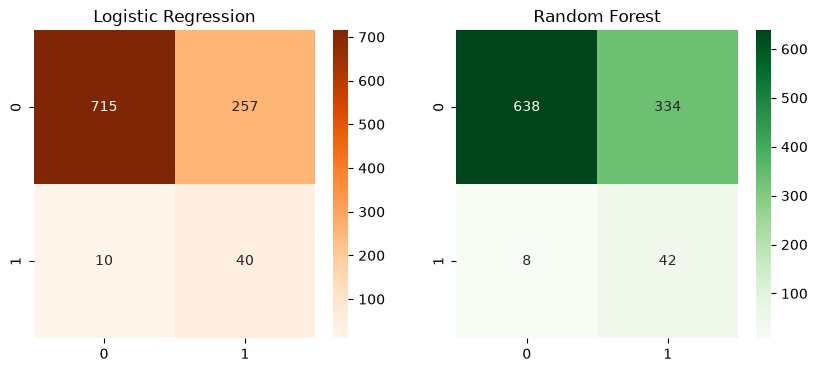

In [68]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.heatmap(confusion_matrix(y_test, pred_lr), annot=True, fmt='d', cmap='Oranges', ax=axes[0])
axes[0].set_title('Logistic Regression')
sns.heatmap(confusion_matrix(y_test, pred_rf), annot=True, fmt='d', cmap='Greens',  ax=axes[1])
axes[1].set_title('Random Forest')
plt.show()

In [69]:
from sklearn.metrics import recall_score, f1_score

summary = pd.DataFrame({
    'Classifier': ['Logistic Regression', 'KNN', 'Decision Tree', 'Random Forest'],
    'Accuracy':   [accuracy_score(y_test, pred_lr), accuracy_score(y_test, pred_knn),
                   accuracy_score(y_test, pred_dt),  accuracy_score(y_test, pred_rf)],
    'Recall':     [recall_score(y_test, pred_lr),    recall_score(y_test, pred_knn),
                   recall_score(y_test, pred_dt),     recall_score(y_test, pred_rf)],
    'F1-Score':   [f1_score(y_test, pred_lr),        f1_score(y_test, pred_knn),
                   f1_score(y_test, pred_dt),          f1_score(y_test, pred_rf)],
})
summary

,Classifier,Accuracy,Recall,F1-Score
0,Logistic Regression,0.738748,0.80,0.230548
1,KNN,0.949119,0.02,0.037037
2,Decision Tree,0.656556,0.78,0.181818
3,Random Forest,0.665362,0.84,0.197183
